# 10C — The NFL Movement Gap

**Question.** The forty-yard dash measures one straight-line acceleration from rest. NFL games expose athletes to more: braking, redirection, re-acceleration, speed holding, repeated speed changes. For each position, how much of the observed game movement can forty tracking physically describe?

**Method (no new computation on tracking).** The 09A demand atlas already holds, per position × demand, the episode counts, contributing athletes and the eligible player-play denominator. Each cell is classified by a rule (`movement_gap.coverage_class`), never by a score:

- *Directly measured* — the 09A registry names a shared forty dimension and the episode starts in the forty's movement state;
- *Partially comparable* — shared dimension, different state;
- *Not directly measured* — no forty analogue;
- *Unavailable* — an analogue exists but the position has too few observed episodes, or no supported prospect comparison (09B).

The exposure index of a position sums its supported demand rates (episodes per 100 eligible player-plays). Categories overlap, so it is an index, not a share of distinct movements; frequency is exposure, not importance to performance.

**Prerequisites.** 09E mart; 10A passed. **Writes.** figures `AM10C_*`, `reports/milestone10/MOVEMENT_GAP_EXECUTIVE_SUMMARY.md`, `reports/tables/advanced_movement/product_v1/movement_gap_*.csv`, `product_v1/movement_gap.json`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
COMPARE = ('OL', 'DB')        # two positions for the comparison section (any two of the mart's positions)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import final_figures as ff
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import movement_gap as mg
from nflbdb.research.advanced_movement.artifacts import ProductStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ProductStore(cfg, controls)
MART = m9.mart_path(store)
m9.assert_valid(m9.validate_mart(MART))
T, EVID, MANIFEST = m9.load_mart(MART)
OV = MANIFEST['overview']
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart built {MANIFEST["built_at"]} · {OV["n_nfl_episodes"]:,} NFL episodes'))

**Run mode: `full`** (FULL) · mart built 2026-10-14T13:13:05Z · 416,507 NFL episodes

## 1 · The demand map and the coverage matrix

demand,forty analogue,comparability
str,str,str
"""acceleration from low speed""","""acc_2_4, acc_4_6""","""same speed bands, same 10 Hz f…"
"""acceleration from intermediate…","""acc_4_6, acc_6_8""","""same speed bands; in the forty…"
"""transition into high-speed run…","""acc_6_8""","""same speed band (6 → 8 yd/s)"""
"""sustained high-speed running""","""top_speed""","""largest speed reached: tracked…"
"""speed maintenance""","""none""","""none: forty recordings usually…"
"""braking and deceleration""","""none""","""none: the forty contains no br…"
"""acceleration following deceler…","""none""","""none: the forty contains no br…"
"""directional redirection""","""none""","""none: the forty is a straight …"
"""repeated speed-change sequence""","""none""","""none: a single maximal sprint …"


label,DB,DL,OL,TE,WR
str,str,str,str,str,str
"""acceleration from low speed""","""Directly measured by forty tra…","""Directly measured by forty tra…","""Directly measured by forty tra…","""Directly measured by forty tra…","""Directly measured by forty tra…"
"""acceleration from intermediate…","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…"
"""transition into high-speed run…","""Directly measured by forty tra…","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Directly measured by forty tra…"
"""sustained high-speed running""","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…","""Partially physically comparabl…"
"""speed maintenance""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)"""
"""braking and deceleration""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)"""
"""acceleration following deceler…","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)"""
"""directional redirection""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)"""
"""repeated speed-change sequence""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)""","""Unavailable (data limitation)"""


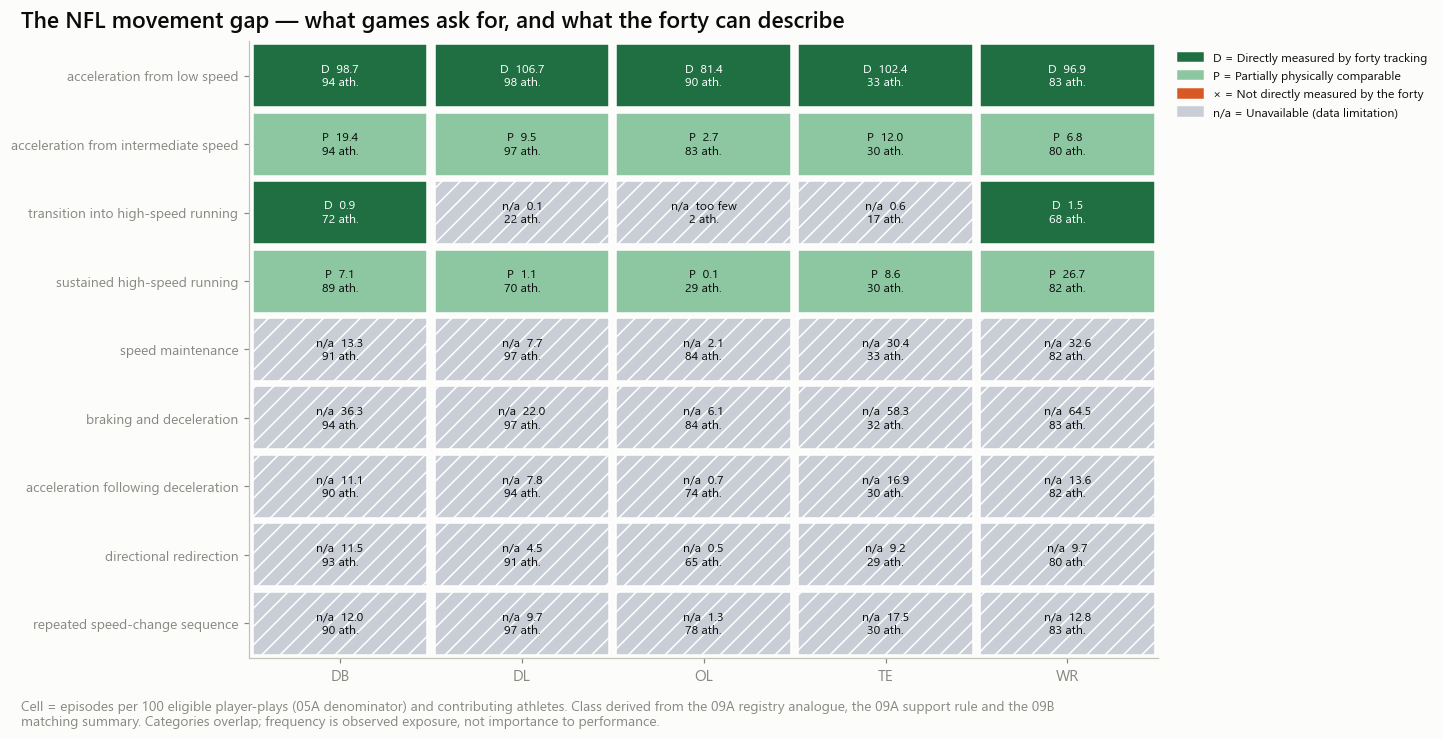

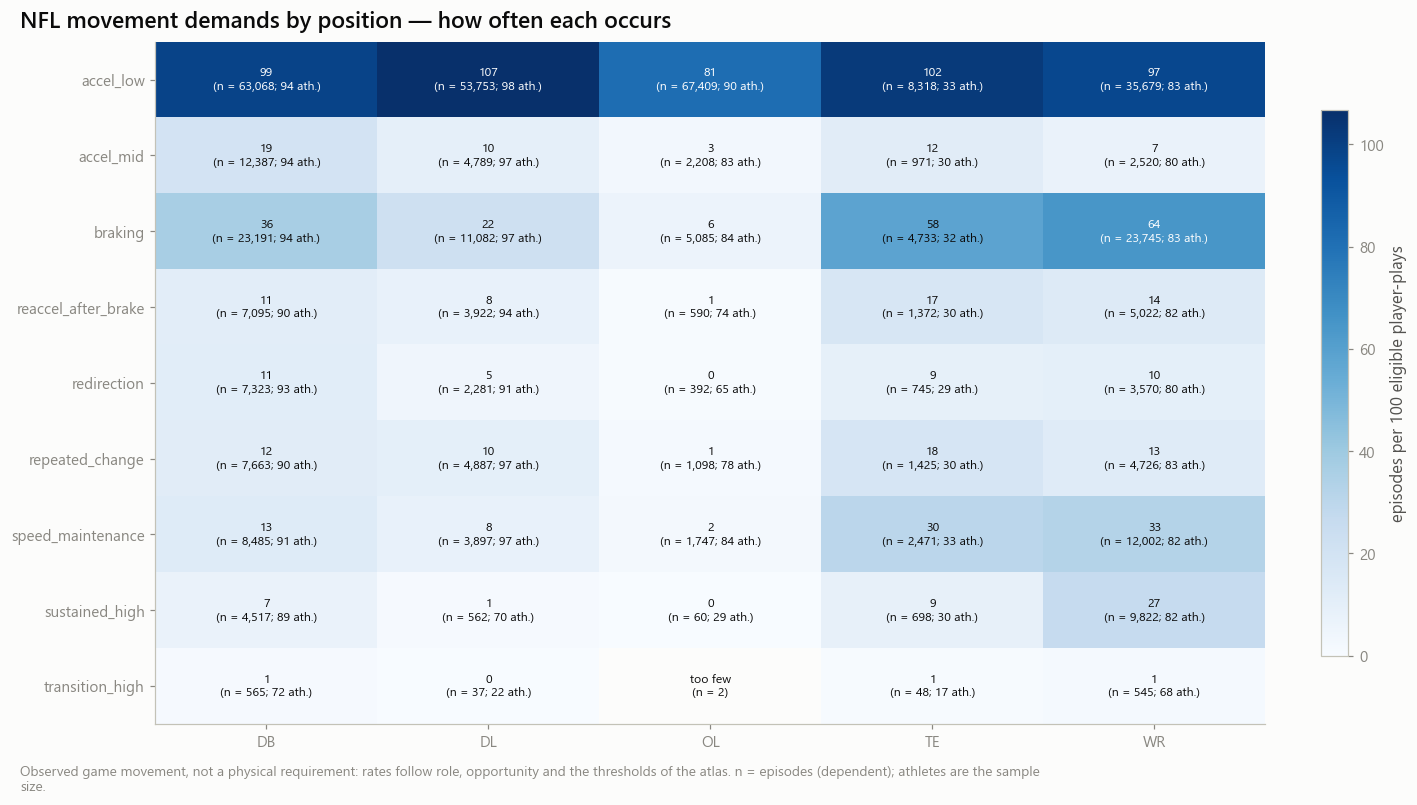

In [3]:
REG = T['nfl_demand_registry'].to_dicts()
G = mg.gap_matrix(REG, T['nfl_movement_demands'].to_dicts(), T['movement_matching_summary'].to_dicts())
GM = pl.DataFrame(G)
display(pl.DataFrame([{'demand': r['label'], 'forty analogue': r['combine_analogue'] or 'none', 'comparability': r['comparability']} for r in REG]))
display(GM.pivot(on='position_group', index='label', values='class_label'))
store.show(ff.fig_movement_gap(G), 'AM10C_01_movement_gap_matrix', {'gap_matrix': GM}, publication=True,
           source='nfl_movement_demands + nfl_demand_registry + movement_matching_summary', n=f'{OV["n_nfl_episodes"]:,} episodes')
store.show(ifg.fig_demand_frequency(T['nfl_movement_demands']), 'AM10C_02_nfl_demands_by_position', {}, publication=True, source='nfl_movement_demands',
           n=f'{OV["n_nfl_episodes"]:,} episodes')

## 2 · The gap by position (with its denominators)

position_group,rate_direct,rate_partial,rate_not_measured,rate_unavailable,rate_total,share_not_measured,share_direct_or_partial,n_supported_demands,n_eligible_plays,min_athletes,n_not_measured,n_unavailable
str,f64,f64,i64,f64,f64,f64,f64,i64,i64,i64,i64,i64
"""DB""",99.560347,26.44804,0,84.108333,210.116719,0.0,0.599707,9,63914,72,0,5
"""DL""",106.731132,10.624863,0,51.835673,169.191668,0.0,0.693628,9,50363,22,0,6
"""OL""",81.405937,2.738932,0,10.762505,94.907374,0.0,0.8866,8,82806,29,0,6
"""TE""",102.387986,20.544067,0,132.865583,255.797637,0.0,0.480583,9,8124,17,0,6
"""WR""",98.338582,33.505267,0,133.198501,265.04235,0.0,0.497444,9,36836,68,0,5


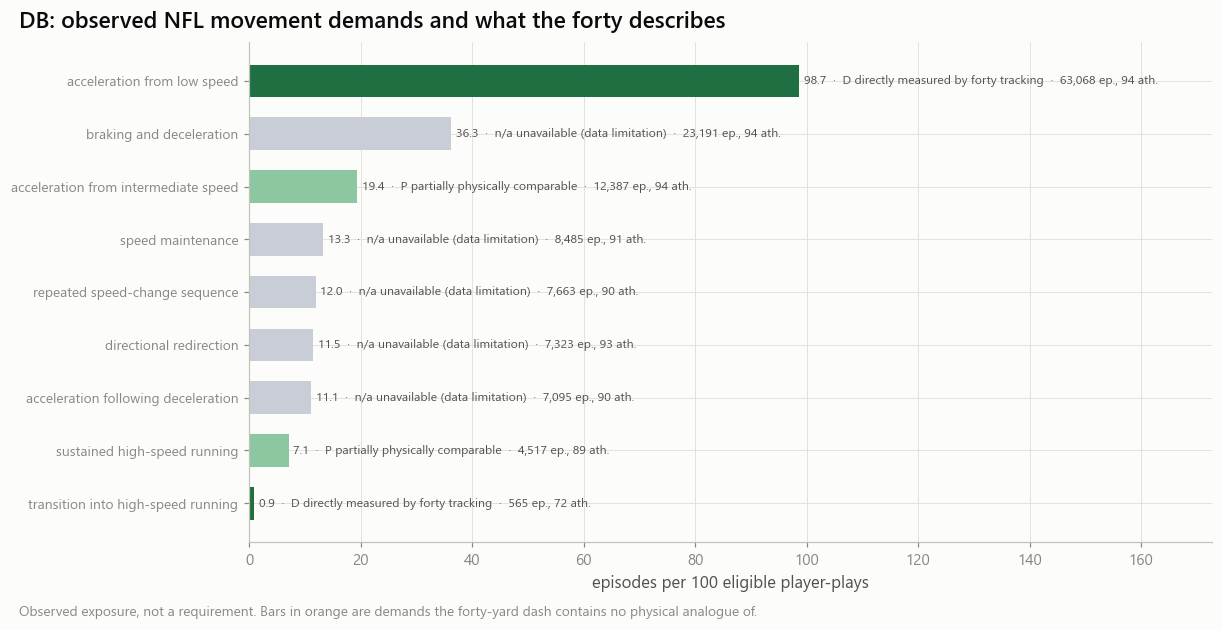

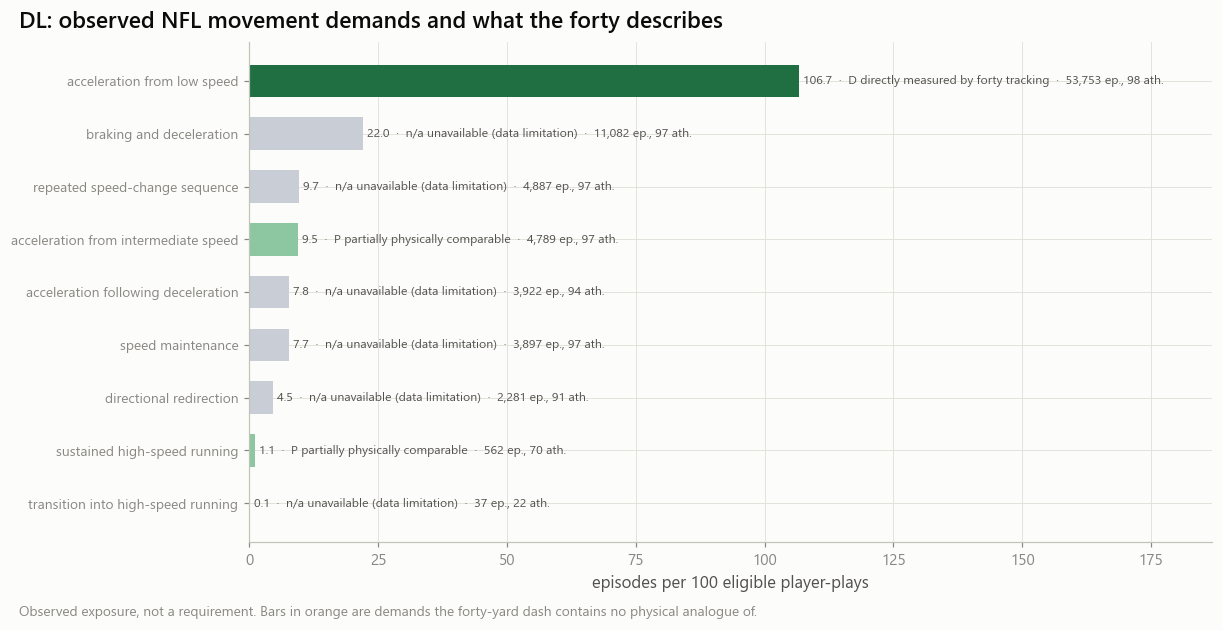

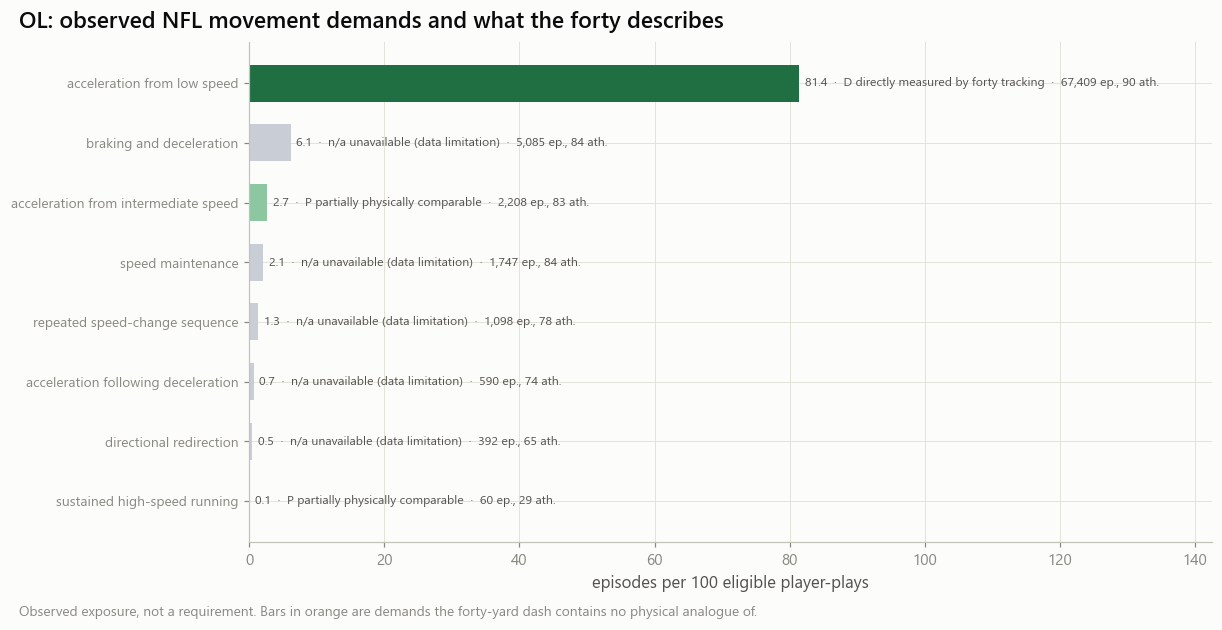

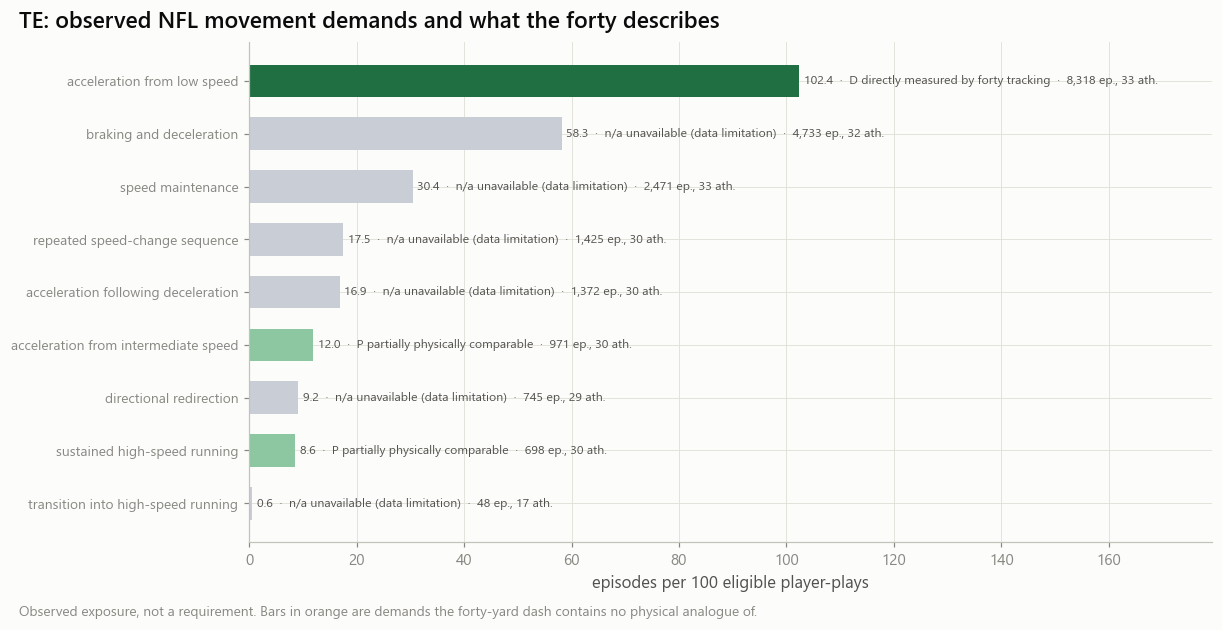

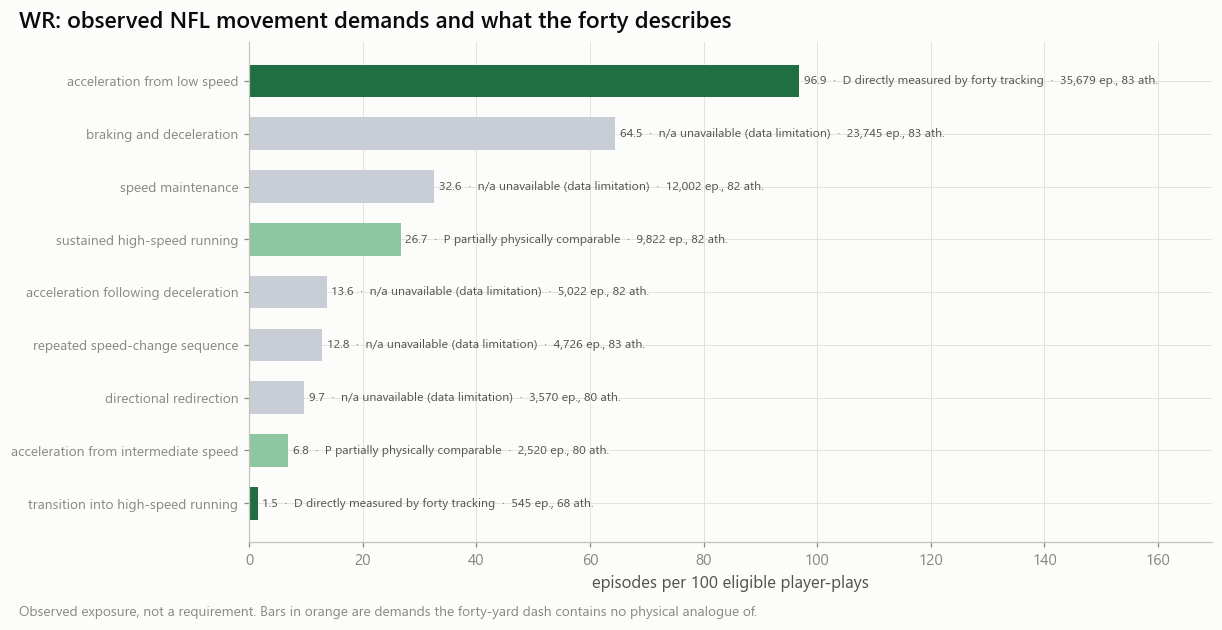

**Largest gap (declared rule):** WR

In [4]:
GS = mg.gap_summary(G)
FOCUS = mg.gap_position(GS)
display(pl.DataFrame(GS))
for s in GS:
    store.show(ff.fig_gap_position(G, s['position_group']), f'AM10C_03_gap_{s["position_group"]}', {}, publication=True, source='gap matrix',
               n=f'{s["n_eligible_plays"]:,} eligible player-plays')
display(Markdown(f"**Largest gap (declared rule):** {FOCUS['position_group'] if FOCUS else 'none — no position meets the support rule'}"))

## 3 · Two positions — is a visible difference a real exposure difference?

Rates, not raw counts, are compared; the flags say when eligible plays or contributing athletes differ enough to mislead the eye.

In [5]:
pa, pb = COMPARE
rows = []
for r in REG:
    c = mg.compare_positions(G, pa, pb, r['demand_id'])
    rows.append({'demand': r['label'], f'{pa} rate': None if not c['a'] else c['a']['episodes_per_100_plays'], f'{pb} rate': None if not c['b'] else c['b']['episodes_per_100_plays'],
                 'ratio b/a': c['rate_ratio_b_over_a'], 'flags': ' | '.join(c['flags'][:-1]) or '—'})
CMP = pl.DataFrame(rows)
display(CMP)

demand,OL rate,DB rate,ratio b/a,flags
str,f64,f64,f64,str
"""acceleration from low speed""",81.405937,98.676346,1.212152,"""—"""
"""acceleration from intermediate…",2.666473,19.38073,7.268301,"""—"""
"""transition into high-speed run…",0.002415,0.884,null,"""OL: too few observed episodes …"
"""sustained high-speed running""",0.072459,7.067309,97.535934,"""OL: only 29 athletes contribut…"
"""speed maintenance""",2.109751,13.275652,6.292522,"""—"""
"""braking and deceleration""",6.140859,36.284695,5.908732,"""—"""
"""acceleration following deceler…",0.712509,11.100854,15.579955,"""—"""
"""directional redirection""",0.473396,11.457584,24.202976,"""—"""
"""repeated speed-change sequence""",1.325991,11.989548,9.041954,"""—"""


## 4 · Candidate measurements for what the forty does not see

Proposed measurement improvements — not proven draft-outcome optimisation. Their value for evaluating prospects would need prospective evidence.

In [6]:
PROPS = pl.DataFrame([{'position': s['position_group'], **p} for s in GS for p in mg.proposals(G, s['position_group'])])
display(PROPS)
print(mg.LIMIT)

position,demand_id,demand,rate,class,test,protocol
str,str,str,str,str,str,str
"""DB""","""accel_mid""","""acceleration from intermediate…","""19.4 per 100 eligible player-p…","""Partially physically comparabl…","""Rolling-start acceleration""","""enter a 10-yd zone at a contro…"
"""DB""","""sustained_high""","""sustained high-speed running""","""7.1 per 100 eligible player-pl…","""Partially physically comparabl…","""Flying sprint""","""a flying 20-yd segment after a…"
"""DB""","""sequence""","""position-specific movement seq…","""combines the demands above""","""proposed""","""DB movement sequence""","""backpedal → plant (brake) → dr…"
"""DL""","""accel_mid""","""acceleration from intermediate…","""9.5 per 100 eligible player-pl…","""Partially physically comparabl…","""Rolling-start acceleration""","""enter a 10-yd zone at a contro…"
"""DL""","""sustained_high""","""sustained high-speed running""","""1.1 per 100 eligible player-pl…","""Partially physically comparabl…","""Flying sprint""","""a flying 20-yd segment after a…"
…,…,…,…,…,…,…
"""TE""","""sustained_high""","""sustained high-speed running""","""8.6 per 100 eligible player-pl…","""Partially physically comparabl…","""Flying sprint""","""a flying 20-yd segment after a…"
"""TE""","""sequence""","""position-specific movement seq…","""combines the demands above""","""proposed""","""TE movement sequence""","""release from an attached stanc…"
"""WR""","""sustained_high""","""sustained high-speed running""","""26.7 per 100 eligible player-p…","""Partially physically comparabl…","""Flying sprint""","""a flying 20-yd segment after a…"


A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.


## 5 · One-page executive summary and outputs

In [7]:
SUMM = mg.executive_summary(GS, G, FOCUS, int(OV['n_nfl_episodes']))
pct = lambda x: '—' if x is None else f'{100 * x:.0f} %'
doc = ['# NFL Movement Gap — executive summary', '', f'_Generated {utc_now()} from mart `{cfg.paths.rel(MART)}` (built {MANIFEST["built_at"]}, run mode {controls.run_mode})._', '']
doc += [f'- {s}' for s in SUMM]
doc += ['', '## Exposure index by coverage class', '', '| Position | Not described by the forty | Direct | Partial | Not measured | Eligible player-plays |', '|---|---|---|---|---|---|']
doc += [f"| {s['position_group']} | {pct(s['share_not_measured'])} | {s['rate_direct']:.1f} | {s['rate_partial']:.1f} | {s['rate_not_measured']:.1f} | {s['n_eligible_plays']:,} |" for s in GS]
doc += ['', '## Candidate measurements', ''] + [f"- **{p['position']} · {p['test']}** — {p['protocol']} (for {p['demand']}, {p['rate']})." for p in PROPS.iter_rows(named=True)]
doc += ['', '_' + mg.LIMIT + '_', '', '![gap](../figures/advanced_movement/product_v1/AM10C_01_movement_gap_matrix.png)']
display(Markdown('\n'.join(doc)))
if controls.save_tables:
    store.reports_dir.mkdir(parents=True, exist_ok=True)
    (store.reports_dir / 'MOVEMENT_GAP_EXECUTIVE_SUMMARY.md').write_text('\n'.join(doc) + '\n', encoding='utf-8')
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    GM.write_csv(store.tables_dir / 'movement_gap_matrix.csv')
    pl.DataFrame(GS).write_csv(store.tables_dir / 'movement_gap_summary.csv')
    PROPS.write_csv(store.tables_dir / 'movement_gap_test_proposals.csv')
    CMP.write_csv(store.tables_dir / f'movement_gap_compare_{pa}_{pb}.csv')
    store.write_json('movement_gap', {'finished_at': utc_now(), 'matrix': G, 'summary': GS, 'focus': FOCUS, 'executive_summary': SUMM, 'engine_version': mg.VERSION,
                                      'mart_built_at': MANIFEST['built_at']})
print('In football terms: the forty answers a straight-line question; the table above shows, position by position, how much of the game asks other questions.')
print('Send back: the class pivot (section 1), the summary table (section 2), and MOVEMENT_GAP_EXECUTIVE_SUMMARY.md.')

# NFL Movement Gap — executive summary

_Generated 2026-10-14T14:24:12Z from mart `warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1` (built 2026-10-14T13:13:05Z, run mode full)._

- The forty-yard dash is one straight-line acceleration from rest. Across 416,507 observed NFL movement episodes, the 09A atlas defines 9 speed-change demands; 9 have a physical analogue in forty tracking and 0 have none ().
- DB: 0 % of the summed exposure rate falls in demands the forty does not describe (0.0 of 210.1 episodes per 100 eligible player-plays; 63,914 eligible player-plays).
- DL: 0 % of the summed exposure rate falls in demands the forty does not describe (0.0 of 169.2 episodes per 100 eligible player-plays; 50,363 eligible player-plays).
- OL: 0 % of the summed exposure rate falls in demands the forty does not describe (0.0 of 94.9 episodes per 100 eligible player-plays; 82,806 eligible player-plays).
- TE: 0 % of the summed exposure rate falls in demands the forty does not describe (0.0 of 255.8 episodes per 100 eligible player-plays; 8,124 eligible player-plays).
- WR: 0 % of the summed exposure rate falls in demands the forty does not describe (0.0 of 265.0 episodes per 100 eligible player-plays; 36,836 eligible player-plays).
- Largest gap: WR — the position whose observed game movement the forty describes least, by this exposure index.
- Categories overlap, so the exposure index is not a share of distinct movements; frequency is exposure, not importance to performance.
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.

## Exposure index by coverage class

| Position | Not described by the forty | Direct | Partial | Not measured | Eligible player-plays |
|---|---|---|---|---|---|
| DB | 0 % | 99.6 | 26.4 | 0.0 | 63,914 |
| DL | 0 % | 106.7 | 10.6 | 0.0 | 50,363 |
| OL | 0 % | 81.4 | 2.7 | 0.0 | 82,806 |
| TE | 0 % | 102.4 | 20.5 | 0.0 | 8,124 |
| WR | 0 % | 98.3 | 33.5 | 0.0 | 36,836 |

## Candidate measurements

- **DB · Rolling-start acceleration** — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (for acceleration from intermediate speed, 19.4 per 100 eligible player-plays).
- **DB · Flying sprint** — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (for sustained high-speed running, 7.1 per 100 eligible player-plays).
- **DB · DB movement sequence** — backpedal → plant (brake) → drive at 45° → close over 5–15 yd; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (for position-specific movement sequence, combines the demands above).
- **DL · Rolling-start acceleration** — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (for acceleration from intermediate speed, 9.5 per 100 eligible player-plays).
- **DL · Flying sprint** — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (for sustained high-speed running, 1.1 per 100 eligible player-plays).
- **DL · DL movement sequence** — get-off from stance → 2-yd burst → redirect toward the quarterback → close; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (for position-specific movement sequence, combines the demands above).
- **OL · Rolling-start acceleration** — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (for acceleration from intermediate speed, 2.7 per 100 eligible player-plays).
- **OL · Flying sprint** — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (for sustained high-speed running, 0.1 per 100 eligible player-plays).
- **OL · OL movement sequence** — pull or set from stance → short burst over 3–5 yd → redirect to the second level; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (for position-specific movement sequence, combines the demands above).
- **TE · Rolling-start acceleration** — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (for acceleration from intermediate speed, 12.0 per 100 eligible player-plays).
- **TE · Flying sprint** — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (for sustained high-speed running, 8.6 per 100 eligible player-plays).
- **TE · TE movement sequence** — release from an attached stance → seam stem → brake → redirect → re-accelerate; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (for position-specific movement sequence, combines the demands above).
- **WR · Flying sprint** — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (for sustained high-speed running, 26.7 per 100 eligible player-plays).
- **WR · Rolling-start acceleration** — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (for acceleration from intermediate speed, 6.8 per 100 eligible player-plays).
- **WR · WR movement sequence** — release → stem at intermediate speed → brake → break at 45–90° → re-accelerate; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (for position-specific movement sequence, combines the demands above).

_A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence._

![gap](../figures/advanced_movement/product_v1/AM10C_01_movement_gap_matrix.png)

In football terms: the forty answers a straight-line question; the table above shows, position by position, how much of the game asks other questions.
Send back: the class pivot (section 1), the summary table (section 2), and MOVEMENT_GAP_EXECUTIVE_SUMMARY.md.
